<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<h1><center><font size=10>Artificial Intelligence and Machine Learning</center></font></h1>



<center> <font size=6> Project Python Foundations: FoodHub Data Analysis

<center><img src="https://www.netsolutions.com/wp-content/uploads/2022/10/essential-features-of-building-an-on-demand-food-ordering-app.jpg" width="720"></center>


### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [1]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [2]:
# Dataset is present in the Google Drive:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Code to read the data
data = pd.read_csv('/content/drive/MyDrive/Great Learning/Project 1 FoodHub/foodhub_order.csv')

#Copying the data to another variable to avoid any changes to original data
food = data.copy()

In [4]:
# Code to view the first 5 rows
food.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [5]:
# Code to view how many rows and columns
food.shape

(1898, 9)

#### Observations:
The dataset has 1898 rows and 9 columns


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [6]:
# Code to view datatypes of the different columns
food.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:

*   All the columns have the same number of observations, 1898, indicating that there are no missing values.
*   The order_id, customer_id,  food_preparation_time and delivery_time columns are all numerical.
*   The cost_of_order column is a float datatype.
*   The restaurant_name, cuisine_type, day_of_the_week and rating columns are all 'object' datatypes.
*   The rating column has data that was labeled "Not given".



### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [7]:
# Code to determine missing values in the data
food.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations:
There doesn't appear to be any missing values in the data.


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [8]:
# Code to view the statistical summary of the data
food.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1898.0,1.477496e+06,548.049724,1476547.00,1477021.25,1477495.50,1.477970e+06,1478444.00
customer_id,1898.0,1.711685e+05,113698.139743,1311.00,77787.75,128600.00,2.705250e+05,405334.00
cost_of_the_order,1898.0,1.649885e+01,7.483812,4.47,12.08,14.14,2.229750e+01,35.41
food_preparation_time,1898.0,2.737197e+01,4.632481,20.00,23.00,27.00,3.100000e+01,35.00
delivery_time,1898.0,2.416175e+01,4.972637,15.00,20.00,25.00,2.800000e+01,33.00


#### Observations:
*   It takes minimum 20 minutes for food to be prepared once an order has been placed.
*   On average, it takes aproximately 27.3 minutes for food to be prepared after an order is placed.
*   It takes maximum 35 minutes for an order of food to be prepared once it's been placed.
*   The information for the columns order_id and customer_id have no real worth in this analysis.
*  The data for the column cost_of_order appears to be slightly right-skewed.







### **Question 5:** How many orders are not rated? [1 mark]

In [10]:
# Code to check the count of each unique category in the variable
food['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### Observations:
There are 736 orders in which the food wasn't rated.


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

#### For Cost of the Order

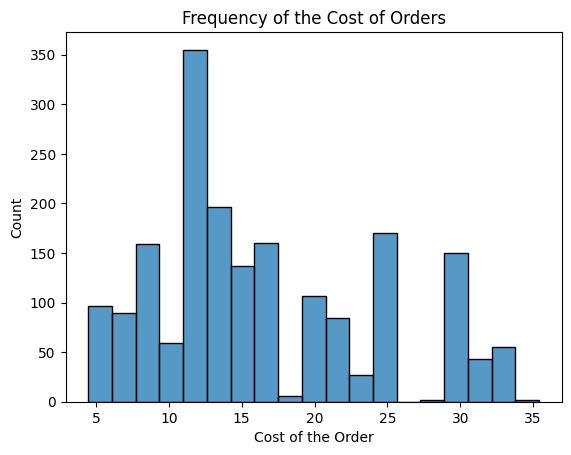

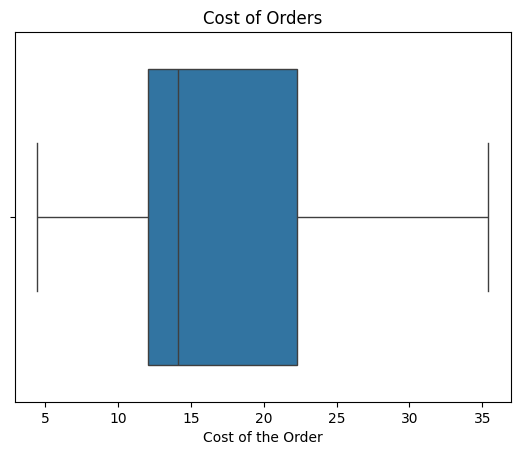

In [11]:
# Code for distributions of the variables

#For Cost of the Order:
sns.histplot(data=food,x='cost_of_the_order')
plt.xlabel("Cost of the Order")
plt.ylabel("Count")
plt.title("Frequency of the Cost of Orders")
plt.show()

sns.boxplot(data=food,x='cost_of_the_order')
plt.xlabel("Cost of the Order")
plt.title("Cost of Orders")
plt.show()

##### Observations:
*  The distribution of costs of the orders is slighlty right skewed.
*  There is no outlier for this variable.
*  The highest amount of orders, around 350, cost aproximately 11-12 dollars.







#### For Day of the Week

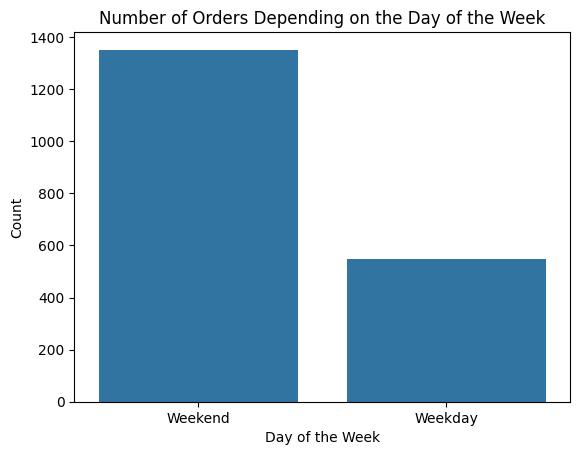

In [12]:
#For Day of the Week:
sns.countplot(data=food,x='day_of_the_week')
plt.xlabel("Day of the Week")
plt.ylabel("Count")
plt.title("Number of Orders Depending on the Day of the Week")
plt.show()


##### Observations:
*   Most orders were placed during the weekend than during weekdays.



#### For Rating

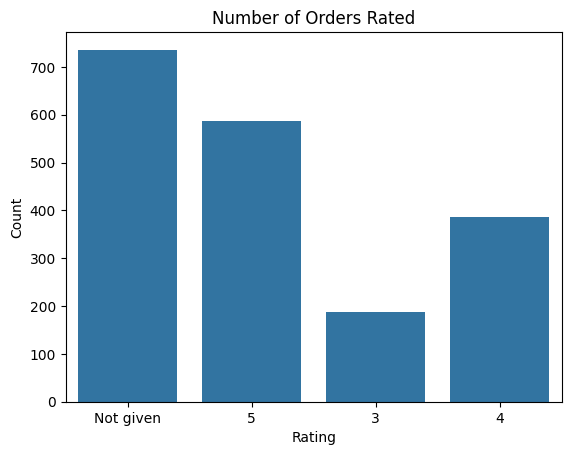

In [13]:
#For Rating:
sns.countplot(data=food,x='rating')
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Number of Orders Rated")
plt.show()

##### Observations:
*  Most food orders weren't given a rating.
*  Of the orders that were given ratings, most recieved 5 stars.
*  Around 580 food orders were given a 5 star rating.
* Of the costumers who rate the orders, most tend to give high ratings.



#### For Food Preparation Time

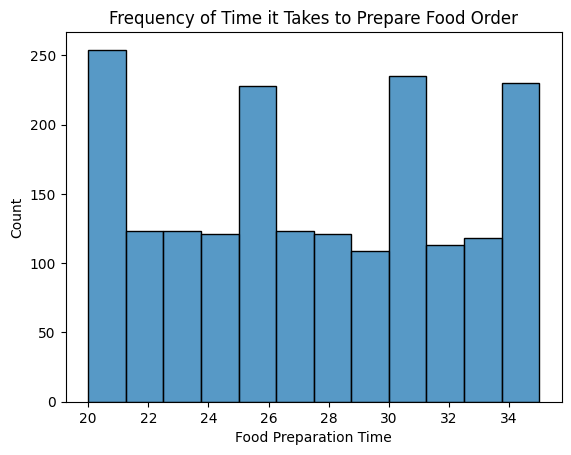

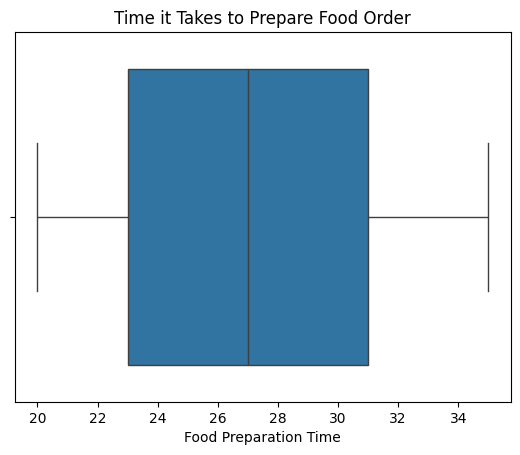

In [14]:
#For Food Preparation Time:
sns.histplot(data=food,x='food_preparation_time')
plt.xlabel("Food Preparation Time")
plt.ylabel("Count")
plt.title("Frequency of Time it Takes to Prepare Food Order")
plt.show()

sns.boxplot(data=food,x='food_preparation_time')
plt.xlabel("Food Preparation Time")
plt.title("Time it Takes to Prepare Food Order")
plt.show()

##### Observations:
*   Most orders, around 250, were prepared in 20-21 minutes.
*   There is not outlier for this variable.
*   In general, the preparation times show a roughly uniform distribution.



#### For Delivery Time

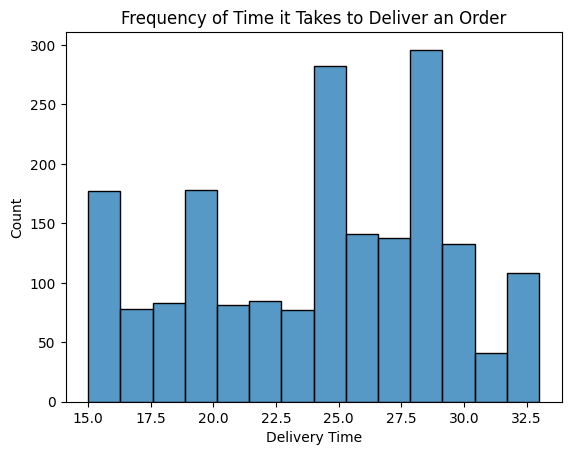

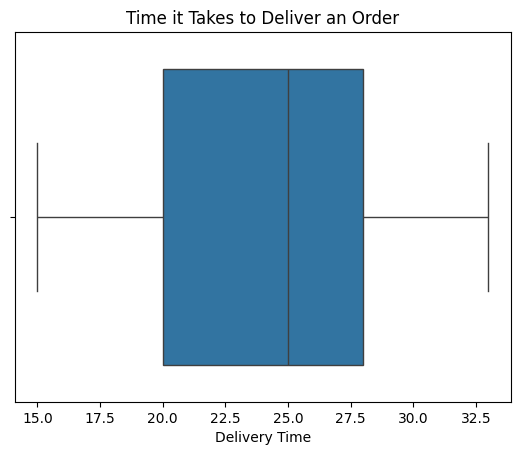

In [15]:
#For Delivery Time:
sns.histplot(data=food,x='delivery_time')
plt.xlabel("Delivery Time")
plt.ylabel("Count")
plt.title("Frequency of Time it Takes to Deliver an Order")
plt.show()

sns.boxplot(data=food,x='delivery_time')
plt.xlabel("Delivery Time")
plt.title("Time it Takes to Deliver an Order")
plt.show()

##### Observations:
*  There are no outliers for this variable.
*  Most orders take around 28-29 minutes to be delivered.





#### For Cuisine Type

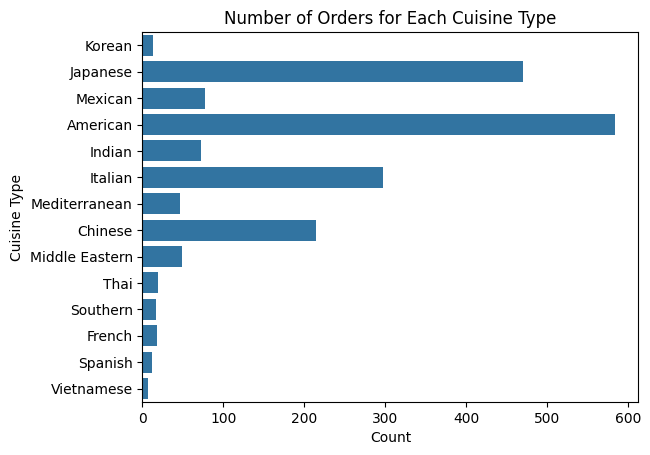

In [16]:
#For Cuisine Type:
sns.countplot(data=food, y='cuisine_type')
plt.xlabel("Count")
plt.ylabel("Cuisine Type")
plt.title("Number of Orders for Each Cuisine Type")
plt.show()

##### Observations:
* Most people order American cuisine followed by Japanese cuisine.
* Vietnamese cuisine is the one ordered the least.
* This graph shows a right-skewed distribution because a small number of cuisines take up a lot of orders. Meanwhile, most cuisines have a little amount of orders.



#### For Customer ID

Text(0.5, 1.0, 'Number of Orders Placed by Customers')

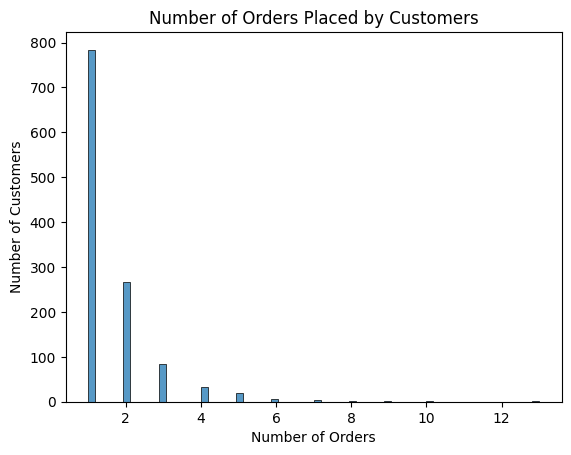

In [17]:
#For Costumer ID:
orders_per_customer = food['customer_id'].value_counts()

sns.histplot(orders_per_customer)
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.title("Number of Orders Placed by Customers")


##### Observations:
* Most customers order only once, though there are some customers that have ordered up to 13 times.
* This could be used to identify potential loyal or high-frequency users. It would be interesting to capitilize on the loyalty and offer rewards to incentivize higher use of the delivery app.



### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

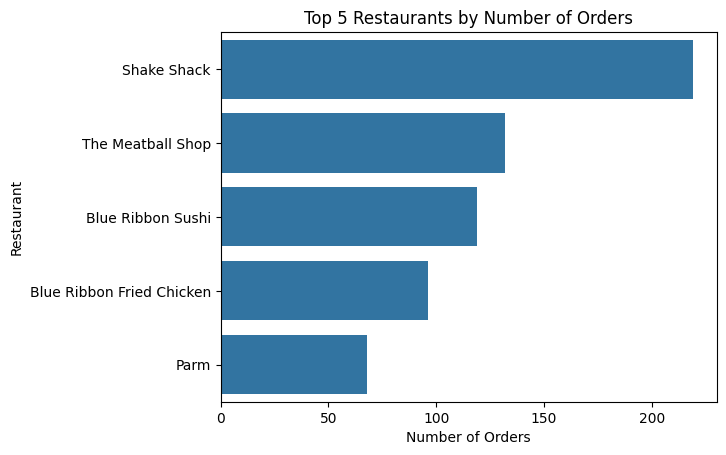

In [18]:
# Code for restaurant popularity in terms of orders recieved
top_restaurants = food['restaurant_name'].value_counts().head(5)

sns.barplot(
    x=top_restaurants.values,
    y=top_restaurants.index
)
plt.xlabel("Number of Orders")
plt.ylabel("Restaurant")
plt.title("Top 5 Restaurants by Number of Orders")
plt.show()



#### Observations:
*   The restaurant Shake Shack has recieved most food orders (more than 200).
*   The top 5 most popular restaurants all have recieved more than 50 orders.




### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

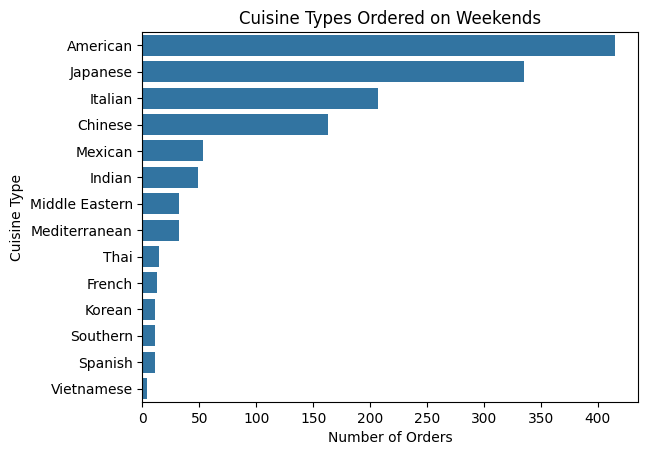

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Middle Eastern,32
Mediterranean,32
Thai,15


In [19]:
# Code to determine most popular cuisines on weekends
weekend_orders = food[food['day_of_the_week'] == 'Weekend']

sns.countplot(
    data=weekend_orders,
    y='cuisine_type',
    order=weekend_orders['cuisine_type'].value_counts().index
)

plt.title("Cuisine Types Ordered on Weekends")
plt.xlabel("Number of Orders")
plt.ylabel("Cuisine Type")
plt.show()

#Table of number of orders per cuisine
weekend_orders['cuisine_type'].value_counts()

#### Observations:
* American cuisine is the most popular on the weekends with 415 orders.




### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [20]:
# Code for calculation of the percentage of orders that cost more than 20 dollars
(food['cost_of_the_order'] > 20).mean() * 100

np.float64(29.24130663856691)

#### Observations:
*   29.24% of orders cost more than 20 dollars. This means that most orders cost less than 20 dollars.




### **Question 10**: What is the mean order delivery time? [1 mark]

In [22]:
# Code for the calculation of the mean order delivery time
food['delivery_time'].mean()

np.float64(24.161749209694417)

#### Observations:
* The mean order delivery time is 24.16 minutes. This might suggest that the delivery time has less of an impact than food preparation time in terms of total delivery time.




### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [23]:
# Code to determine the top 3 most frequent customers and their IDs
food['customer_id'].value_counts().head(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:
*   The top customer's ID is 52832 and they have ordered 13 times.
*   The second most frquent customer's ID is 47440 and they have ordered food through the app 10 times.
*   The third most frequent customer's ID is 83287 and they have ordered 9 times.





### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


#### Correlation between numerical values

In [24]:
# Code to change column of "Rating"
food2 = data.copy() #New copy of the dataset

food2['rating'] = food2['rating'].replace('Not given', np.nan) # Repalcing "Not given" labels as NaN
food2['rating'] = pd.to_numeric(food2['rating']) # Changing 'Rating' variable to numeric
food2.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1162 non-null   float64
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(2), int64(4), object(3)
memory usage: 133.6+ KB


In [27]:
# Code to determine numerical data
food2.select_dtypes(exclude=['object', 'category']).columns

Index(['order_id', 'customer_id', 'cost_of_the_order', 'rating',
       'food_preparation_time', 'delivery_time'],
      dtype='object')

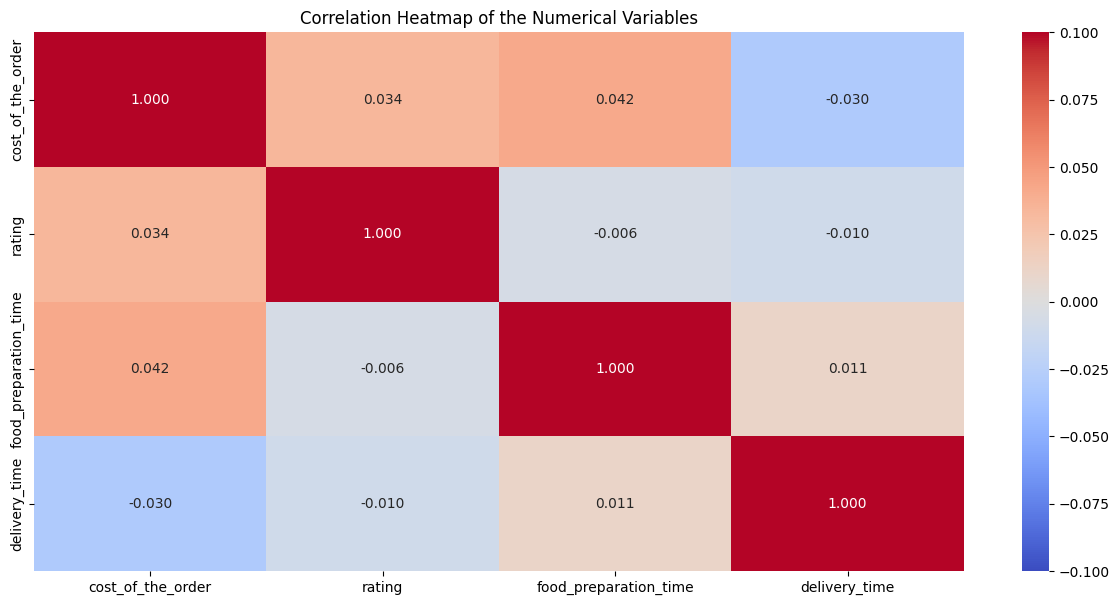

In [28]:
# Selecting only the numerical columns
num_varfood2 = food2[['cost_of_the_order', 'rating', 'food_preparation_time', 'delivery_time']].columns

# Check for correlation among numerical variables
corr = food2[num_varfood2].corr(numeric_only = True)

# Plot the heatmap
plt.figure(figsize=(15, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-0.1,
    vmax=0.1
)
plt.title("Correlation Heatmap of the Numerical Variables")
plt.show()

##### Observations:
* It is important to note that these correlations are all actually very weak. While slight positive and negative correlations exist, for example between time of preparation of food and cost of order or between rating and delivery time, these values are too small to indicate any meaningful linear relationships. Overall it seems these variables may be independent from each other.






#### Cuisine by rating analysis

In [29]:
#Code to visualize the average ratings according to the type of cuisine
avg_rating_cuisine = food2.groupby('cuisine_type')['rating'].mean().sort_values()
avg_rating_cuisine

,rating
cuisine_type,
Vietnamese,4.000000
Korean,4.111111
Mediterranean,4.218750
Middle Eastern,4.235294
American,4.298913
French,4.300000
Southern,4.307692
Chinese,4.338346
Italian,4.360465


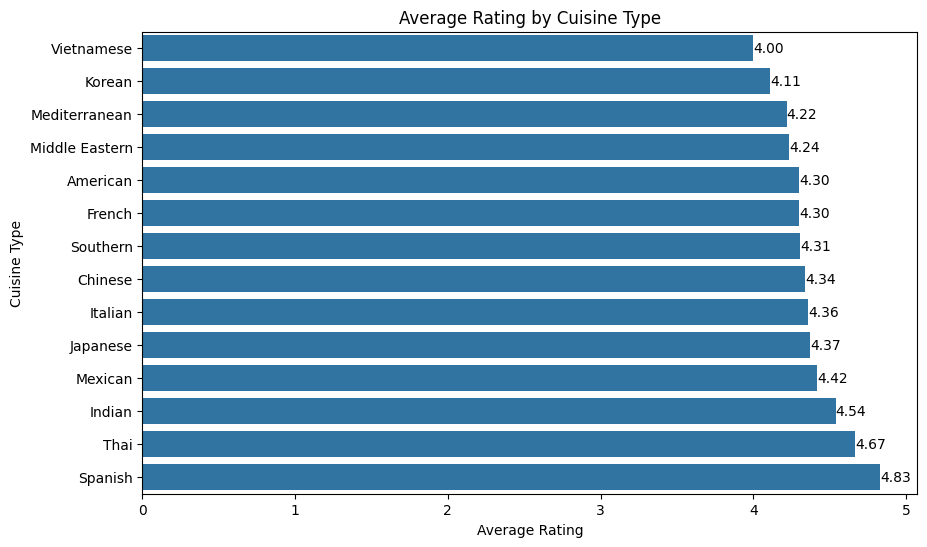

In [30]:
#Bare graph to visualize the table shown before
plt.figure(figsize=(10,6))

sns.barplot(
    x=avg_rating_cuisine.values,
    y=avg_rating_cuisine.index
)

plt.xlabel("Average Rating")
plt.ylabel("Cuisine Type")
plt.title("Average Rating by Cuisine Type")

for i, v in enumerate(avg_rating_cuisine.values):
    plt.text(v, i, f"{v:.2f}", va='center') #adds values of average ratings to each bar
plt.show()





##### Observations:
* Ratings are consistently high across all cuisine types.
* Spanish cuisine seems to be the one higher rated amongst all the other cuisines.



#### Delivery time on weekdays vs weekends

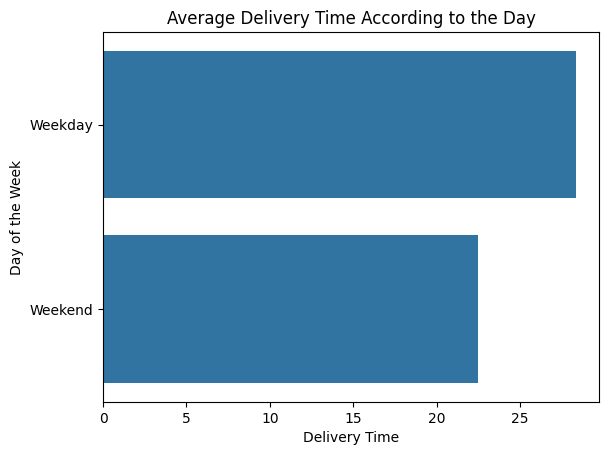

In [31]:
#Comparison of delivery time on weekdays vs weekends
day_delivery=food2.groupby('day_of_the_week')['delivery_time'].mean()

sns.barplot(
    x=day_delivery.values,
    y=day_delivery.index
)

plt.xlabel("Delivery Time")
plt.ylabel("Day of the Week")
plt.title("Average Delivery Time According to the Day")
plt.show()

##### Observations:
* Delivery of an order takes aproximately 6 more minutes to arrive to the costumer on weekdays compared to weekends.


#### How many restaurants belong to each cuisine type

In [32]:
#Counting the unique restaurants for each cuisine
restaurant_counts = food2.groupby('cuisine_type')['restaurant_name'].nunique().sort_values(ascending=False)
restaurant_counts

,restaurant_name
cuisine_type,
American,41
Italian,31
Japanese,29
Chinese,16
Indian,14
Mexican,11
Thai,9
Middle Eastern,7
Korean,5


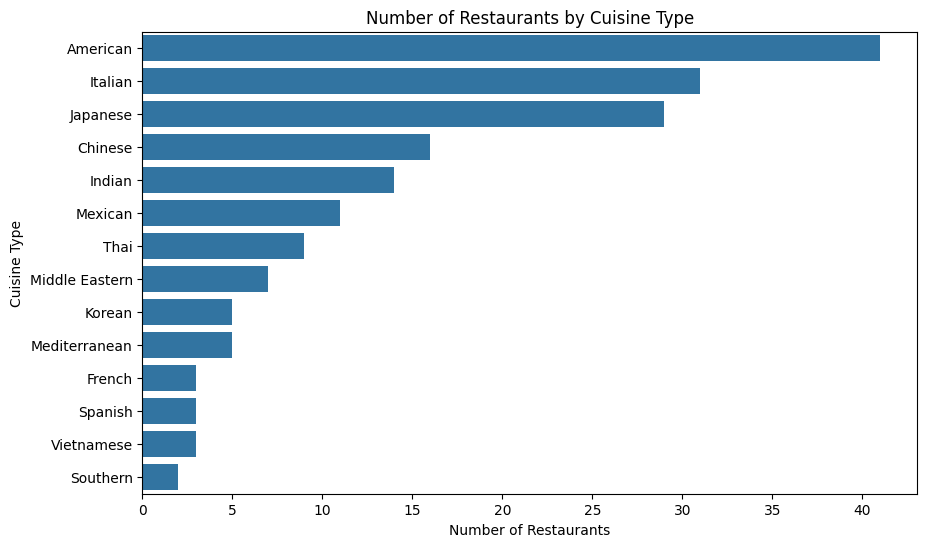

In [ ]:
# Plot of the table shown before
plt.figure(figsize=(10,6))

sns.barplot(
    x=restaurant_counts.values,
    y=restaurant_counts.index
)

plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine Type")
plt.title("Number of Restaurants by Cuisine Type")

plt.show()

##### Observations:
* Most restaurants serve an American cuisne.
* Restaurants with cuisines like Southern, Vietnamese and Spanish are less available. This could influence aspects like availability and ordering patterns.



#### Cost vs rating analysis

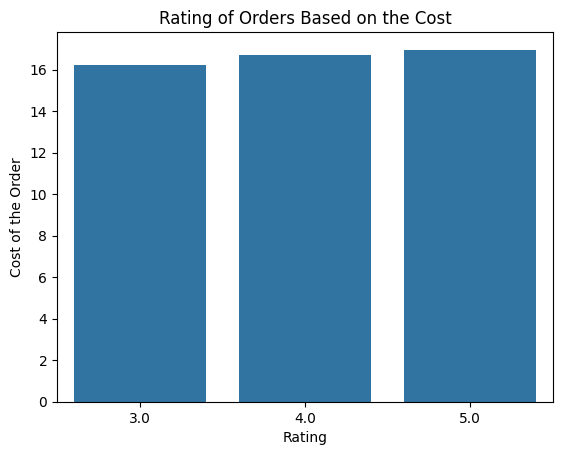

In [33]:
sns.barplot(data=food2, x= 'rating', y='cost_of_the_order', errorbar=None)
plt.title("Rating of Orders Based on the Cost")
plt.xlabel("Rating")
plt.ylabel("Cost of the Order")
plt.show()

##### Observations:
* It looks like the cost slightly increases with higher ratings. It could indicate that more expensive foods generate a slighlty better experience, but this difference is very minimal and likely not significant.


### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [35]:
# Code to determine the rating count and average rating of restaurants
# Using the dataset titled 'food2' previously created where the column 'Rating' is numerical and "Not given" labels have been replaced for NaN
restaurant_rating = (
    food2.groupby('restaurant_name')['rating']
        .agg(['count', 'mean'])
)                                                #Grouping dataset by the restaurant names and their ratings

filtered_restaurants = restaurant_rating[
    (restaurant_rating['count'] > 50) & (restaurant_rating['mean'] > 4)
]                                                                        #Filtering so it meets the conditions stated

filtered_restaurants.sort_values(by='mean', ascending=False)


,count,mean
restaurant_name,,
The Meatball Shop,84,4.511905
Blue Ribbon Fried Chicken,64,4.328125
Shake Shack,133,4.278195
Blue Ribbon Sushi,73,4.219178


##### Observations:
* Four restaurants fulfill the criteria to get the promotional offer.
* Although the restaurant Shake Shack has the highest rating count, the restaurant The Meatball Shop has the highest average rating.
* All these restaurants have consistent customer satisfaction as evidenced by their ability to mantain their rating well above 4 stars.



### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [36]:
# Code to determine the net revenue generated by the company across all orders
def commission(cost):
    if cost > 20:
        return cost * 0.25
    elif cost > 5:
        return cost * 0.15
    else:
        return 0

revenue = food['cost_of_the_order'].apply(commission).sum()
revenue

np.float64(6166.303)

##### Observations:
* The company generated a net revenue of 6166.30 dollars across all orders.
* Higher value orders seem to bring the most revenue to the company.



### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [37]:
# Code for total time required to deliver the food
total_time = food['food_preparation_time'] + food['delivery_time']

percentage_delivered = (total_time > 60).mean() * 100

percentage_delivered

np.float64(10.537407797681771)

##### Observations:
* Around 10.54% of orders take more than 60 minutes to get delivered from the time the order is placed.
* This low percentage implies that the delivery system is reliable.




### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [38]:
# Code to calculate mean delivery during days of the week
food.groupby('day_of_the_week')['delivery_time'].mean()

,delivery_time
day_of_the_week,
Weekday,28.340037
Weekend,22.470022


##### Observations:
* The mean delivery time is longer during the weekdays, which may be due to other external factors like traffic.
* Weekends have a faster delivery time of aproximately 6 minutes than weekdays.






### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
* Most orders cost around 11 to 12 dollars, on the lower end of the spectrum.
* Even though American cuisine is the most ordered, Spanish cuisine is the one with the highest ratings. This might mean that costumer behavior might be influenced by visibility, pricing and convenience, not just the quality of the food.  
* The ratings of costumer satisfaction are consistently high across cuisines.
* The restaurants that meet the promotional offer criteria show strong costumer trust and consistent performance, which might indicate that they are key strategic partners for the platform.
* As observed in the correlation heatmap, delivery and preparation had little effect on the ratings. It is therefore assumed that time-related factors don't impact the rating score in a significant way.
* Most amount of orders are placed during the weekends. However, there seems to be a higher delivery wait time on the weekdays. It might mean that there is another factor that influences major delays on weekdays that doesn't affect as much on weekends such as traffic.
* Restaurants like The Meatball Shop have a high rating and a large number of reviews.
* There are many restaurants that are only ordered from once and a small group that have a lot of orders. This could mean that there are clear favorite restaurants that costumers choose to order from.

### Recommendations:

* The app could prioritize partnerships with the restaurants that perform well and attract a high volume of costumers.
* The company could implement a rewards program to benefit and incentivize loyalty from the costumers that order the most because this is a small group of users.
* Since weekends perform better, analyze what is working and, if possible, apply the same strategies for better weekday efficiency.
* The company could highlight the popular cuisines, but could also look to expand the availabilty of other less represented cuisines to drive more engagement.
*  More data could be collected on other factors like peak order and delivery hours to increase personnel during those times and avoid any possible delays.
* The company could implement personal recomendations based on the user's behaviors by using their cuisine preferences and their past ratings to increase their engagement and their order value.




---